# IMPORTAR E VISUALIZAR IMAGENS

### Neste exercício utilizaremos o conjunto de dados da FEI.
- Faça o download do conjunto de dados: https://fei.edu.br/~cet/frontalimages_manuallyaligned_part1.zip
- Descompacte o conjunto e dados no mesmo diretório deste arquivo

### No primeiro exemplo vamos importar uma imagem com a biblioteca Pillow
- Utilizaremos a função **open()**, da classe **Image**, que retorna um objeto de imagem que contém os dados de pixel da imagem

##### Passo 1: Importar as bibliotecas necessárias

In [1]:
# Caso não tenha a biblioteca instalada, remova o comentário da linha abaixo na primeira vez que executar este bloco
#!pip install pillow
from PIL import Image

##### Passo 2: Importar uma imagem da conjunto de dados

In [2]:
# Carregando a imagem
file = Image.open('frontalimages_manuallyaligned_part1/1b.jpg')

##### Passo 3: Visualizar imagem

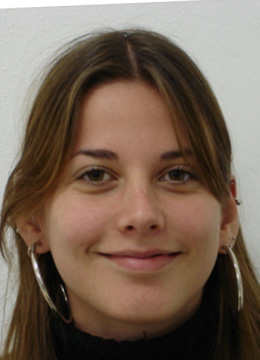

In [3]:
# Apresentando a imagem carregada na variável file
file

##### Passo 4: Visualizar as propriedades da imagem

In [4]:
# Modo da imagem
print(file.mode)

RGB


In [5]:
# Formato da imagem
print(file.format)

JPEG


In [6]:
# Tamanho da imagem (largura, altura)
print(file.size)

(260, 360)


### No segundo exemplo vamos importar uma imagem com a biblioteca Matplotlib
- utilizares a função **mpimg** do módulo **matplotlib.image** que nos permite carregar uma imagem como um **numpy.ndarray 3D**, sendo cada dimensão um canal de cor, **RED**, **GREEN**, **BLUE** e cada lista interna representa um pixel.

##### Passo 1: Importar as bibliotecas necessárias

In [7]:
#!pip install matplotlib
from matplotlib import pyplot as plt
import matplotlib.image as mpimg

##### Passo 2: Importar uma imagem da conjunto de dados

In [53]:
# Carrega a imagem como um array de pixels
data = mpimg.imread('frontalimages_manuallyaligned_part1/1b.jpg')

##### Passo 3: Visualizar array

In [50]:
# Imprime os arrays de dados
data

array([[255, 255, 255, ..., 200, 200, 202],
       [255, 255, 255, ..., 199, 200, 202],
       [255, 255, 255, ..., 200, 202, 203],
       ...,
       [ 88,  85,  82, ...,  36,  38,  36],
       [ 78,  76,  76, ...,  35,  38,  36],
       [ 75,  73,  74, ...,  32,  36,  35]], shape=(360, 260), dtype=uint8)

##### Passo 4: Visualizar as propriedades da array

In [10]:
# Imprime o tipo 
type(data)

numpy.ndarray

In [11]:
# Tipo de dados
data.dtype

dtype('uint8')

In [12]:
# Dimensão de dados
data.shape

(360, 260, 3)

##### Passo 5: Visualizar a array de pixels como uma imagem

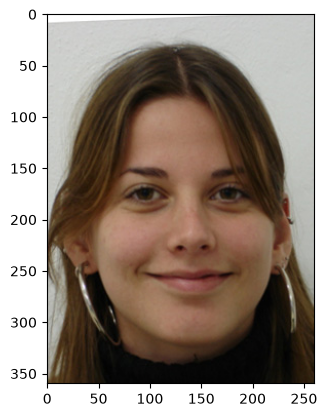

In [54]:
# Apresentando o array de pixels como uma imagem
plt.imshow(data)
plt.axis('on')
plt.show()

### No terceiro exemplo vamos utilizar as bibliotecas Pillow, Matplotlib e Numpy
Neste exemplo vamos carregar uma imagem com a função **open()** e iremos converter a imagem em tons de cinza com a função **convert('L')**, em seguida utilizaremos a função **np.array()** para carregarmos a imagem como um **numpy.ndarray**.

##### Passo 1: Importar as bibliotecas necessárias

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

##### Passo 2: Importar uma imagem da conjunto de dados

In [55]:
# Carrega a imagem
imagem = Image.open('frontalimages_manuallyaligned_part1/1a.jpg')
# Converte em tons de cinza
imagem_tons_cinza = imagem.convert("L")
# Converte em array
data = np.array(imagem_tons_cinza)

##### Passo 3: Visualizar imagem em tons de cinza e dimensão da array

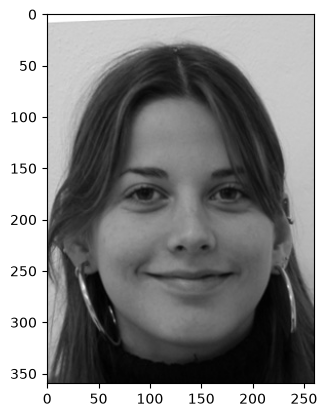

In [59]:
# Apresentando a imagem carregada na variável data
plt.imshow(data, cmap='gray')
plt.axis('on')
plt.show()

In [60]:
# Dimensão da array
data.shape

(360, 260)

### No quarto exemplo iremos carregar multiplas imagens como array
Neste exemplo, além das bibliotecas anteriores, vamos utilizar a biblioteca **glob** para listar os arquivos do diretório. 

##### Passo 1: Importar as bibliotecas necessárias

In [18]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import glob

##### Passo 2: Criar um conjunto de dados com todas as imagens do diretório

In [61]:
# Criando uma variável para armazenar as imagens
dataset = []

# Criando um laço de repetição para importar cada imagem
for file in glob.glob("frontalimages_manuallyaligned_part1/*.jpg"):
    # Carredando a imagem do índice
    load_file = Image.open(file)
    # Convertendo a imagem e tons de cinza
    load_file = load_file.convert("L")
    # Convertendo o objeto imagem em array
    load_file = np.array(load_file)
    # Adicionando a array da na variável dataset
    dataset.append(load_file)
# Convertendo a lista de imagens em array
dataset = np.array(dataset)

In [62]:
# Dimensão do conjunto de dados
dataset.shape

(200, 360, 260)

##### Passo 3: Visualizar imagens do conjunto de dados pelo índice

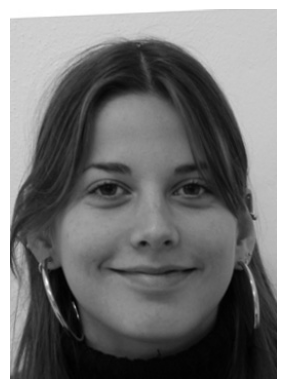

In [66]:
# Apresentando uma imagem qualquer da variável dataset
plt.imshow(dataset[22,:,:], cmap='gray')
plt.axis('off')
plt.show()

# Imagem média do conjunto de dados
- Nesta etapa iremos obter um primeiro padrão, calculando a imagem média do conjunto de dados

In [22]:
# Obtendo a dimensão das imagens
lx = dataset.shape[1]
ly = dataset.shape[2]

# Criando uma variável para armazenar as imagem média
mean_file = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        mean_file[x,y] = round(np.mean(dataset[:,x,y]))

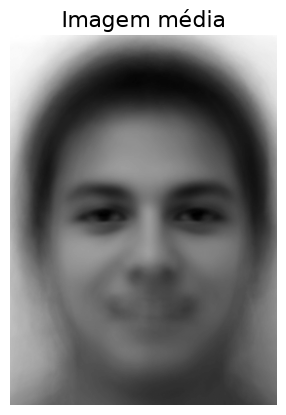

In [23]:
# Apresentando uma imagem média do conjunto de dados dataset
plt.imshow(mean_file, cmap='gray')
plt.title('Imagem média', fontsize=16)
plt.axis('off')
plt.show()

## Subconjuntos da classe de Faces
- No conjunto de dados de face da FEI há dois subconjuntos, sendo um de faces neutras e outro de faces sorrindo
- Vamos repetir o processo anterir para calcular a imagem média de cada classe

In [24]:
# Criando uma variável para armazenar as imagens neutras
dataset_neutral = []

# Criando um laço de repetição para importar cada imagem
for file in glob.glob("frontalimages_manuallyaligned_part1/*a.jpg"):
    # Carredando a imagem do índice
    load_file = Image.open(file)
    # Convertendo a imagem e tons de cinza
    load_file = load_file.convert("L")
    # Convertendo o objeto imagem em array
    load_file = np.array(load_file)
    # Adicionando a array da na variável dataset
    dataset_neutral.append(load_file)
# Convertendo a lista de imagens em array
dataset_neutral = np.array(dataset_neutral)

In [25]:
# Dimensão do conjunto de dados
dataset_neutral.shape

(100, 360, 260)

In [26]:
# Obtendo a dimensão das imagens
lx = dataset_neutral.shape[1]
ly = dataset_neutral.shape[2]

# Criando uma variável para armazenar as imagem média
mean_file_neutral = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        mean_file_neutral[x,y] = round(np.mean(dataset_neutral[:,x,y]))

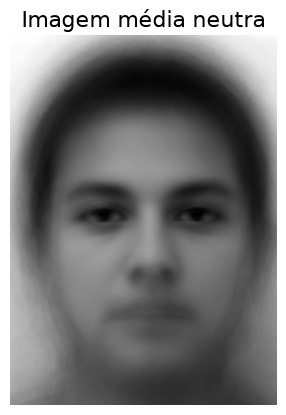

In [27]:
# Apresentando uma imagem média do conjunto de dados
plt.imshow(mean_file_neutral, cmap='gray')
plt.title('Imagem média neutra', fontsize=16)
plt.axis('off')
plt.show()

In [28]:
# Criando uma variável para armazenar as imagens sorrindo
dataset_smiling = []

# Criando um laço de repetição para importar cada imagem
for file in glob.glob("frontalimages_manuallyaligned_part1/*b.jpg"):
    # Carredando a imagem do índice
    load_file = Image.open(file)
    # Convertendo a imagem e tons de cinza
    load_file = load_file.convert("L")
    # Convertendo o objeto imagem em array
    load_file = np.array(load_file)
    # Adicionando a array da na variável dataset
    dataset_smiling.append(load_file)
# Convertendo a lista de imagens em array
dataset_smiling = np.array(dataset_smiling)

In [29]:
# Dimensão do conjunto de dados
dataset_smiling.shape

(100, 360, 260)

In [30]:
# Obtendo a dimensão das imagens
lx = dataset_smiling.shape[1]
ly = dataset_smiling.shape[2]

# Criando uma variável para armazenar as imagem média
mean_file_smiling = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        mean_file_smiling[x,y] = round(np.mean(dataset_smiling[:,x,y]))

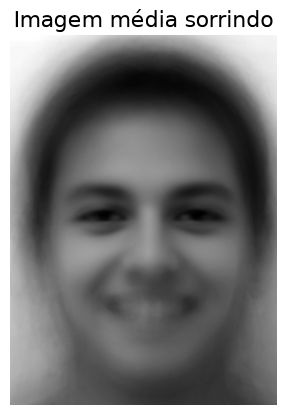

In [31]:
# Apresentando uma imagem média do conjunto de dados
plt.imshow(mean_file_smiling, cmap='gray')
plt.title('Imagem média sorrindo', fontsize=16)
plt.axis('off')
plt.show()

##### Visualização das imagens médias por categoria

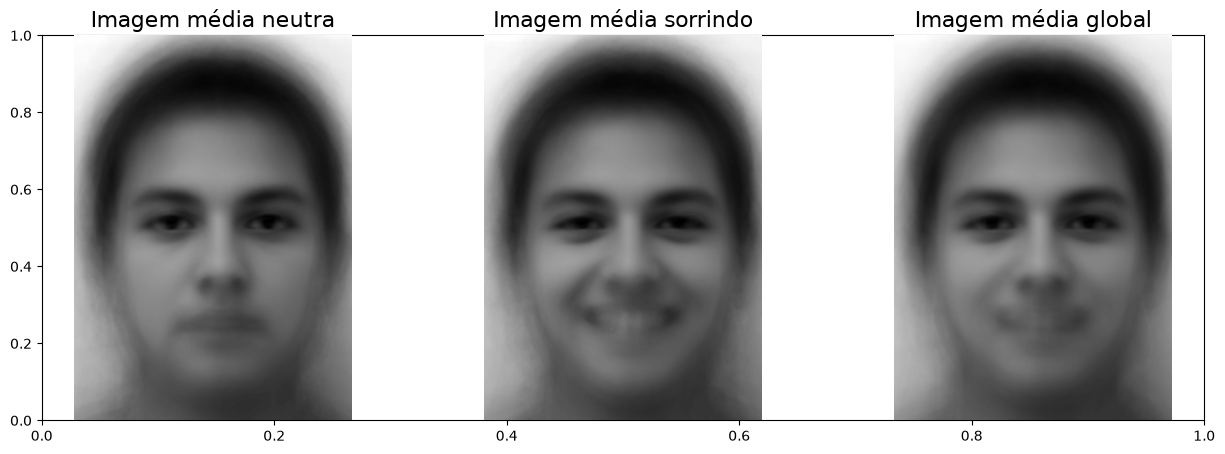

In [32]:
# Apresentando um comparativo das imagens geradas

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização da imagem média neutra 
plt.subplot(1,3,1)
plt.imshow(mean_file_neutral, cmap='gray')
plt.title('Imagem média neutra', fontsize=16)
plt.axis('off')

# Configurando a visualização da imagem média sorrindo 
plt.subplot(1,3,2)
plt.imshow(mean_file_smiling, cmap='gray')
plt.title('Imagem média sorrindo', fontsize=16)
plt.axis('off')

# Configurando a visualização da imagem média global
plt.subplot(1,3,3)
plt.imshow(mean_file, cmap='gray')
plt.title('Imagem média global', fontsize=16)
plt.axis('off')

# Apresentando a comparação de todas as imagens
plt.show()

## Distância Euclidiana da Média
- Nesta etapa iremos calcular a distância Euclidiana entre cada imagem do conjunto de dados com relação a imagem média.

In [33]:
# Calculando a diferença de uma imagem qualquer em relação a imagem média
diferenca = dataset[0,:,:]-mean_file

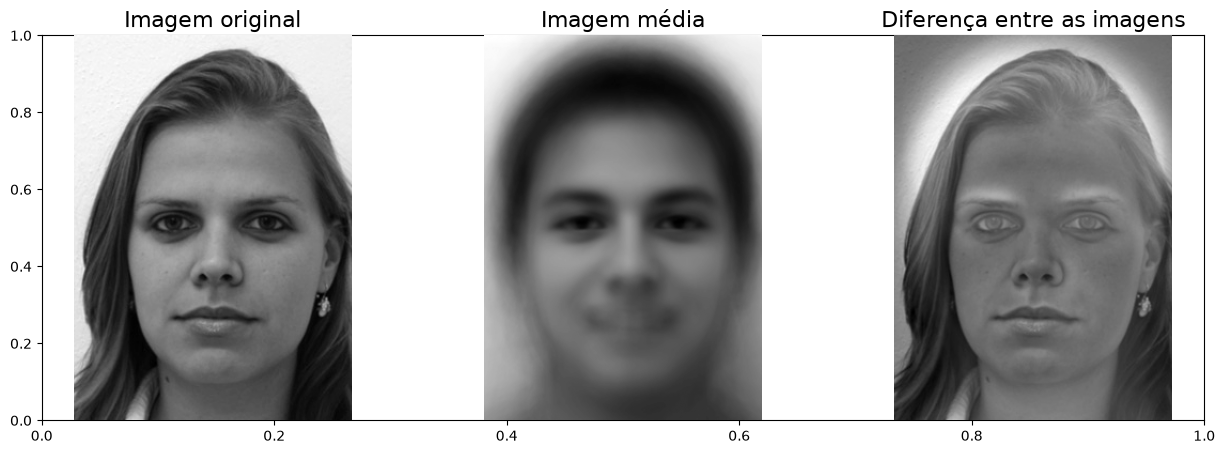

In [34]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização da imagem original
plt.subplot(1,3,1)
plt.imshow(dataset[0,:,:], cmap='gray')
plt.title('Imagem original', fontsize=16)
plt.axis('off')

# Configurando a visualização da imagem média
plt.subplot(1,3,2)
plt.imshow(mean_file, cmap='gray')
plt.title('Imagem média', fontsize=16)
plt.axis('off')

# Configurando a visualização da diferença
plt.subplot(1,3,3)
plt.imshow(diferenca, cmap='gray')
plt.title('Diferença entre as imagens', fontsize=16)
plt.axis('off')

# Apresentando o resultado
plt.show()

In [35]:
# Valores da difença entre as imagens
diferenca

array([[ -3.,  -5.,  -4., ...,  -4.,  -4.,  -2.],
       [ -3.,  -2.,  -1., ...,  -1.,  -1.,   0.],
       [ -4.,   0.,   0., ...,  -1.,  -2.,  -1.],
       ...,
       [-70., -57., -53., ..., -65., -64., -63.],
       [-66., -54., -55., ..., -64., -63., -63.],
       [-59., -56., -63., ..., -61., -61., -62.]], shape=(360, 260))

Observem que alguns pixels vão receber valores negativos, pois o valor do pixel local da imagem média pode ser maior que o valor do pixel da imagem original.

Vejamos essa diferença pelo histograma das imagens

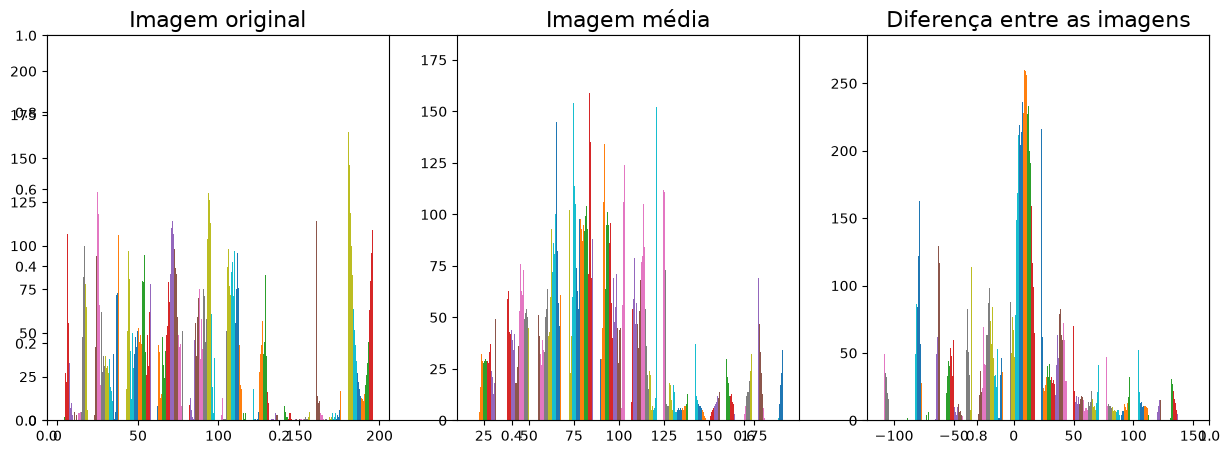

In [36]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização da imagem original
plt.subplot(1,3,1)
plt.hist(dataset[0,:,:])
plt.title('Imagem original', fontsize=16)

# Configurando a visualização da imagem média
plt.subplot(1,3,2)
plt.hist(mean_file)
plt.title('Imagem média', fontsize=16)

# Configurando a visualização da diferença
plt.subplot(1,3,3)
plt.hist(diferenca)
plt.title('Diferença entre as imagens', fontsize=16)

# Apresentando o resultado
plt.show()

### Difença absoluta

A diferença absoluta de cada imagem pode ser obtida pela somatória do módulo da diferença entre a cada imagem e a imagem média, conforme equação a seguir, em que **I** repesenta uma imagem da lista e **M** a imagem média.
$$∑|I_{ji}-M_{ji}|$$


In [37]:
# Exemplo de implementação desta equação para uma imagem qualquer da lista
np.sum(abs(dataset[2,:,:]-mean_file))

np.float64(2511025.0)

### Obtendo a diferença absoluta de todas as imagens

In [38]:
# Obtendo a dimensão do conjunto de imagens neutras
indice = dataset_neutral.shape[0]

# Criando variáveis para armazenar a diferença das imagens
dif_neutral_mean_file = np.zeros([indice])
dif_neutral_mean_neutral = np.zeros([indice])
dif_neutral_mean_smiling = np.zeros([indice])

# Criando um laço de repetição para calcular a diferença entre as imagens
for img in range(indice):
    dif_neutral_mean_file[img] = np.sum(abs(dataset_neutral[img,:,:]-mean_file))
    dif_neutral_mean_neutral[img] = np.sum(abs(dataset_neutral[img,:,:]-mean_file_neutral))
    dif_neutral_mean_smiling[img] = np.sum(abs(dataset_neutral[img,:,:]-mean_file_smiling))

In [39]:
# Empilhamento das arrays de diferença
dif_neutral = np.stack((dif_neutral_mean_file, dif_neutral_mean_neutral,dif_neutral_mean_smiling), axis=1)
dif_neutral

array([[2912733., 2933068., 2933060.],
       [2511025., 2498734., 2585174.],
       [3365436., 3320217., 3420117.],
       [2278892., 2307529., 2257595.],
       [2946467., 2909476., 3002752.],
       [2488619., 2479860., 2532522.],
       [2735009., 2728564., 2752872.],
       [3537497., 3591946., 3486326.],
       [2431317., 2388668., 2506994.],
       [2390154., 2399297., 2437779.],
       [2625839., 2632846., 2668798.],
       [4324943., 4345024., 4323996.],
       [2021272., 2033871., 2066013.],
       [2694413., 2681890., 2736262.],
       [2218199., 2246108., 2244512.],
       [1987426., 2025525., 1998679.],
       [2361249., 2358730., 2396968.],
       [2221987., 2264752., 2215516.],
       [2454146., 2478977., 2494233.],
       [2562275., 2481110., 2651764.],
       [3716176., 3692381., 3745895.],
       [2806926., 2759201., 2863391.],
       [2947884., 2883699., 3024607.],
       [2627045., 2647972., 2637566.],
       [2651208., 2596247., 2725029.],
       [2559098., 2514755

### Repetindo o processo para as imagens da classe sorrindo

In [40]:
# Obtendo a dimensão do conjunto de imagens sorrindo
indice = dataset_smiling.shape[0]

# Criando variáveis para armazenar a diferença das imagens
dif_smiling_mean_file = np.zeros([indice])
dif_smiling_mean_neutral = np.zeros([indice])
dif_smiling_mean_smiling = np.zeros([indice])

# Criando um laço de repetição para calcular a diferença entre as imagens
for img in range(indice):
    dif_smiling_mean_file[img] = np.sum(abs(dataset_smiling[img,:,:]-mean_file))
    dif_smiling_mean_neutral[img] = np.sum(abs(dataset_smiling[img,:,:]-mean_file_neutral))
    dif_smiling_mean_smiling[img] = np.sum(abs(dataset_smiling[img,:,:]-mean_file_smiling))

In [41]:
# Empilhamento das arrays de diferença
dif_smiling = np.stack((dif_smiling_mean_file, dif_smiling_mean_neutral,dif_smiling_mean_smiling), axis=1)
dif_smiling

array([[3140936., 3242733., 3057977.],
       [2431803., 2466500., 2414262.],
       [3258166., 3243797., 3302269.],
       [2239330., 2268979., 2216223.],
       [2962664., 3003383., 2948389.],
       [2391368., 2395487., 2420789.],
       [2917398., 2984007., 2880149.],
       [3539525., 3601016., 3480866.],
       [2272899., 2315808., 2267872.],
       [2381542., 2409067., 2377027.],
       [2674219., 2692454., 2705084.],
       [4324943., 4345024., 4323996.],
       [2104938., 2149817., 2073723.],
       [2610834., 2658477., 2605339.],
       [2463210., 2550023., 2386387.],
       [2083269., 2131964., 2047116.],
       [2271613., 2333820., 2247578.],
       [2402785., 2471700., 2351498.],
       [2326222., 2365041., 2312451.],
       [2581562., 2541961., 2655365.],
       [3694453., 3735244., 3685022.],
       [2707949., 2738656., 2714478.],
       [2719281., 2694982., 2769890.],
       [2653423., 2687822., 2655526.],
       [2471370., 2500311., 2481185.],
       [2576635., 2620314

### Visualização das diferenças

C:\Users\34345054826\AppData\Local\Temp\ipykernel_36128\1704687484.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dif_neutral, vert = 1)
C:\Users\34345054826\AppData\Local\Temp\ipykernel_36128\1704687484.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dif_smiling, vert = 1)


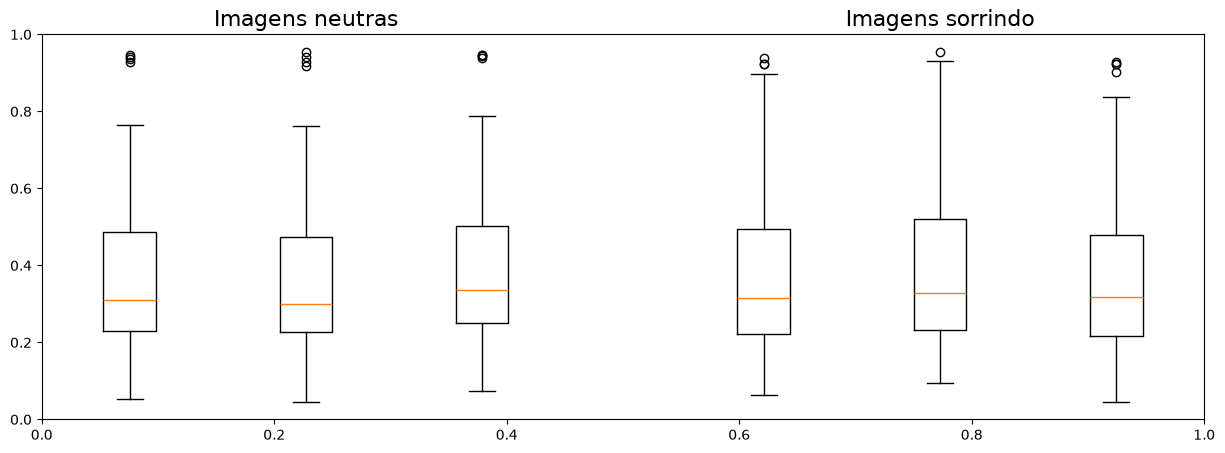

In [42]:
# Apresentando o resultado da diferença das imagens
import matplotlib.pyplot as plt
# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização das imagens neutras
plt.subplot(1,2,1)
plt.boxplot(dif_neutral, vert = 1)
plt.title('Imagens neutras', fontsize=16)
plt.axis('off')

# Configurando a visualização das imagens sorrindo
plt.subplot(1,2,2)
plt.boxplot(dif_smiling, vert = 1)
plt.title('Imagens sorrindo', fontsize=16)
plt.axis('off')

# Visualização dos resultados
plt.show()

### Visualizando os dados com SEABORN

##### Passo 1: Importar as bibliotecas necessárias

In [43]:
#!pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

##### Passo 2: Configuração dos dados de visualização

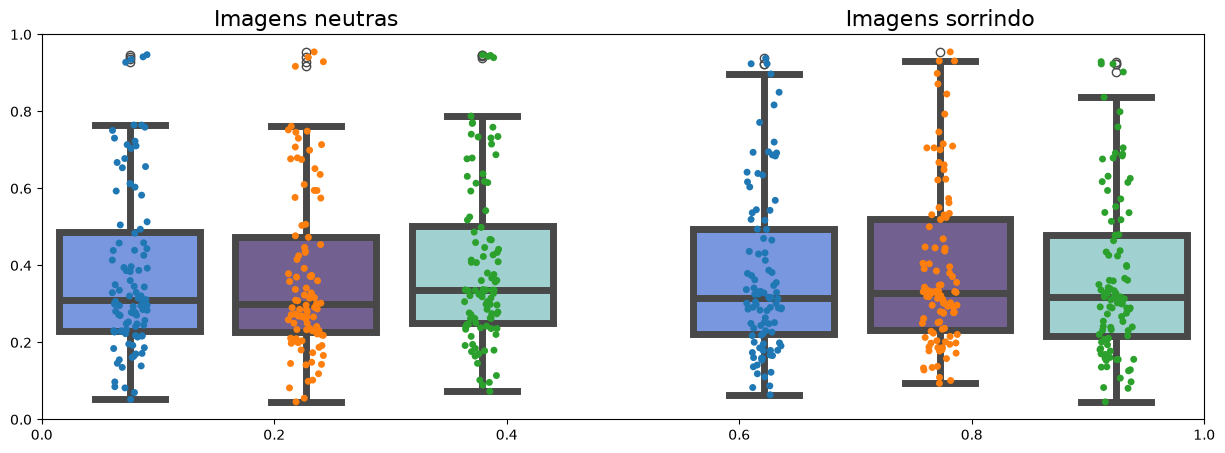

In [44]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a paleta de cores dos boxplot
colors = ['#6890F0', '#705898', '#98D8D8']

# Configurando a visualização das imagens neutras
plt.subplot(1,2,1)
plt.title('Imagens neutras', fontsize=16)
plt.axis('off')
# plot das diferenças em relação a médias das classes
sns.boxplot(data = dif_neutral, linewidth=5, palette=colors)
# Gráfico de disperção
sns.stripplot(data = dif_neutral) 

# Configurando a visualização das imagens sorrindo
plt.subplot(1,2,2)
plt.title('Imagens sorrindo', fontsize=16)
plt.axis('off')
# plot das diferenças em relação a médias das classes
sns.boxplot(data = dif_smiling, linewidth=5, palette=colors)
# Gráfico de disperção
sns.stripplot(data = dif_smiling) 

# Visualização dos resultados
plt.show()

# EXERCÍCIO

Nós vimos nos passos anteriores como calcular a média das imagens e a respectiva distância entre cada imagem.
- Considere repetir esses passos para calcular a diferença entre as imagens a partir de outros padrões como a **mediana** e a **moda**, ao final, compare os resultados.

## Mediana

In [76]:
# Obtendo a dimensão das imagens
lx = dataset_smiling.shape[1]
ly = dataset_smiling.shape[2]

# Criando uma variável para armazenar as imagem média
median_file_neutral = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        median_file_neutral[x,y] = round(np.mean(dataset_neutral[:,x,y]))


# Obtendo a dimensão das imagens
lx = dataset_neutral.shape[1]
ly = dataset_neutral.shape[2]

# Criando uma variável para armazenar as imagem média
median_file_smiling = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        median_file_neutral[x,y] = round(np.mean(dataset_smiling[:,x,y]))        

In [77]:
# Obtendo a dimensão das imagens
lx = dataset.shape[1]
ly = dataset.shape[2]

# Criando uma variável para armazenar as imagem média
median_file = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        median_file[x,y] = round(np.median(dataset[:,x,y]))

# Obtendo a dimensão do conjunto de imagens neutras
indice = dataset_neutral.shape[0]

# Criando variáveis para armazenar a diferença das imagens
dif_neutral_median_file = np.zeros([indice])
dif_neutral_median_neutral = np.zeros([indice])
dif_neutral_median_smiling = np.zeros([indice])

# Criando um laço de repetição para calcular a diferença entre as imagens
for img in range(indice):
    dif_neutral_median_file[img] = np.sum(np.median(dataset_neutral[img,:,:]-median_file))
    dif_neutral_median_neutral[img] = np.sum(np.median(dataset_neutral[img,:,:]-median_file_neutral))
    dif_neutral_median_smiling[img] = np.sum(np.median(dataset_neutral[img,:,:]-median_file_smiling))

In [78]:
dif_smiling = np.stack((dif_neutral_median_file, dif_neutral_median_neutral,dif_neutral_median_smiling), axis=1)
dif_smiling

array([[  3.,   5.,  80.],
       [ -8., -11.,  70.],
       [  6.,  -1.,  64.],
       [-11., -12.,  71.],
       [ -8., -12.,  62.],
       [  0.,   2.,  82.],
       [ 14.,  19., 107.],
       [-15., -15.,  69.],
       [ -1.,   1.,  86.],
       [ -5.,  -6.,  80.],
       [ -5.,  -5.,  74.],
       [ 17.,  18.,  98.],
       [ -8.,  -7.,  77.],
       [  1.,  -3.,  70.],
       [ -4.,   0.,  86.],
       [ -4.,  -1.,  83.],
       [  7.,  10.,  94.],
       [-10.,  -9.,  74.],
       [ -8.,  -5.,  82.],
       [  8.,  11.,  99.],
       [ 11.,  16.,  90.],
       [  6.,   7.,  88.],
       [  4.,   7.,  93.],
       [ 12.,  17., 104.],
       [  7.,   7.,  84.],
       [  5.,   7.,  92.],
       [ -9.,  -6.,  75.],
       [ 10.,   7.,  73.],
       [ -2.,  -2.,  79.],
       [  7.,  11., 102.],
       [ 11.,   6.,  75.],
       [  0.,  -1.,  73.],
       [ -3.,  -7.,  69.],
       [  0.,   4.,  91.],
       [-15., -19.,  60.],
       [  1.,   3.,  86.],
       [ -8.,  -9.,  67.],
 

In [47]:
dif_neutral_median_file

array([  5., -11.,  -1., -13., -12.,   2.,  18., -17.,   0.,  -6.,  -5.,
        18.,  -8.,  -2.,  -1.,  -2.,   9., -10.,  -5.,  12.,  16.,   7.,
         7.,  16.,   7.,   7.,  -6.,   7.,  -1.,  11.,   7.,  -1.,  -6.,
         4., -19.,   3.,  -9.,  16.,  -2.,   1.,   0.,  13.,   3.,  -3.,
        -9.,  12.,   1., -16.,  -8.,  -3.,  -4.,  -6.,  -5.,  20.,  -9.,
         9., -14.,  -6.,  10.,  17.,   2.,  -7.,   0.,  10.,   4.,  -9.,
        19.,  23.,  -2.,   7.,   8.,   5.,  -2.,  17.,  -2.,   4.,  16.,
         4.,  -6.,   3.,   1., -13.,  17.,   9.,  18.,  20.,   3.,   3.,
        -4.,   2.,  10.,   7., -10.,   4., -10.,  11.,   4.,   9.,  23.,
        -6.])

C:\Users\34345054826\AppData\Local\Temp\ipykernel_36128\778092651.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dif_neutral, vert = 1)
C:\Users\34345054826\AppData\Local\Temp\ipykernel_36128\778092651.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(dif_smiling, vert = 1)


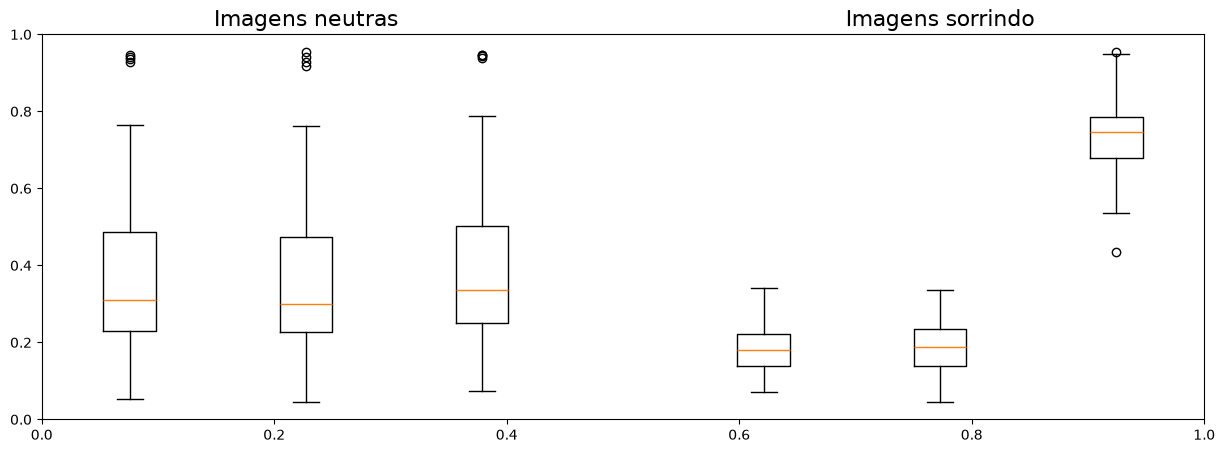

In [79]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização das imagens neutras
plt.subplot(1,2,1)
plt.boxplot(dif_neutral, vert = 1)
plt.title('Imagens neutras', fontsize=16)
plt.axis('off')

# Configurando a visualização das imagens sorrindo
plt.subplot(1,2,2)
plt.boxplot(dif_smiling, vert = 1)
plt.title('Imagens sorrindo', fontsize=16)
plt.axis('off')

# Visualização dos resultados
plt.show()

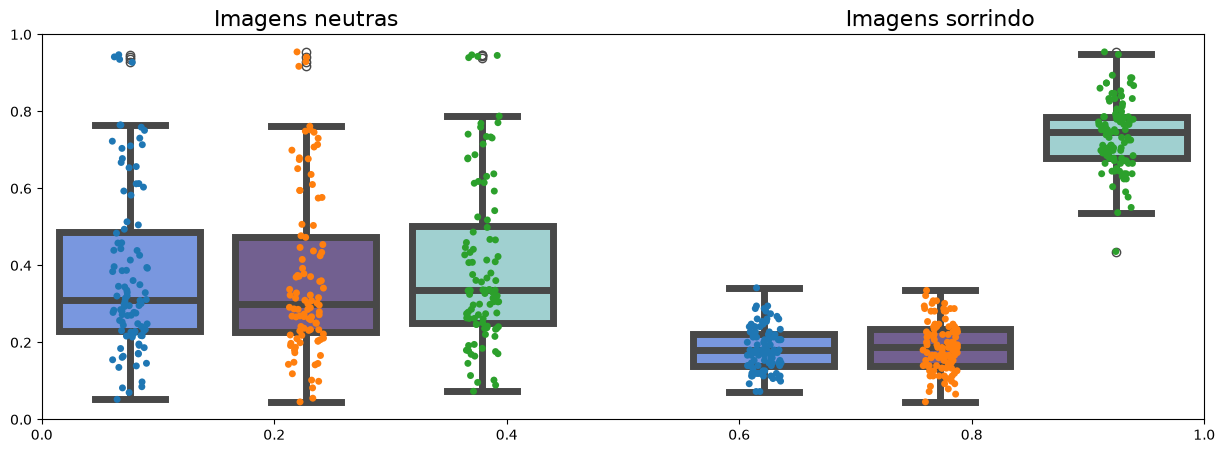

In [80]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a paleta de cores dos boxplot
colors = ['#6890F0', '#705898', '#98D8D8']

# Configurando a visualização das imagens neutras
plt.subplot(1,2,1)
plt.title('Imagens neutras', fontsize=16)
plt.axis('off')
# plot das diferenças em relação a médias das classes
sns.boxplot(data = dif_neutral, linewidth=5, palette=colors)
# Gráfico de disperção
sns.stripplot(data = dif_neutral) 

# Configurando a visualização das imagens sorrindo
plt.subplot(1,2,2)
plt.title('Imagens sorrindo', fontsize=16)
plt.axis('off')
# plot das diferenças em relação a médias das classes
sns.boxplot(data = dif_smiling, linewidth=5, palette=colors)
# Gráfico de disperção
sns.stripplot(data = dif_smiling) 

# Visualização dos resultados
plt.show()

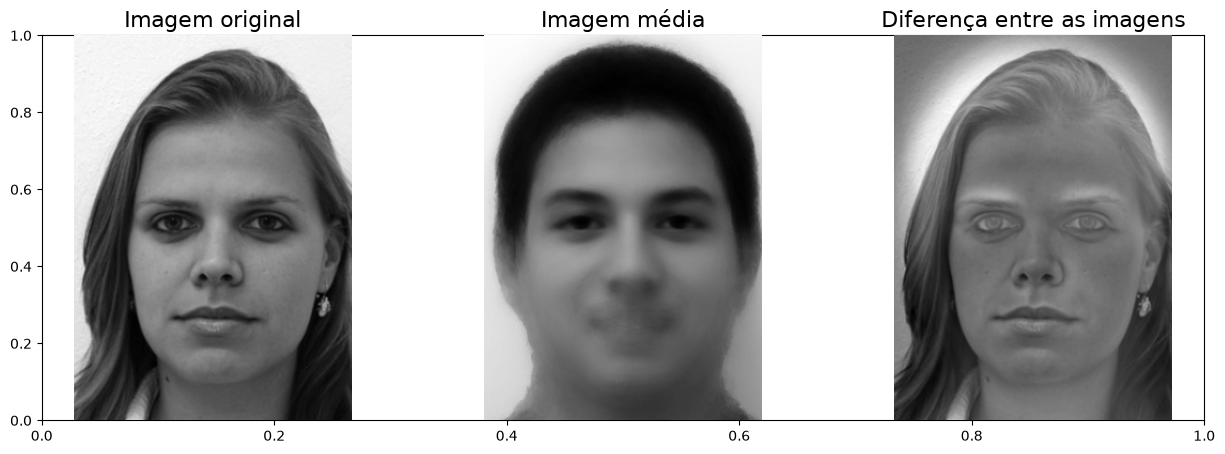

In [81]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização da imagem original
plt.subplot(1,3,1)
plt.imshow(dataset[0,:,:], cmap='gray')
plt.title('Imagem original', fontsize=16)
plt.axis('off')

# Configurando a visualização da imagem média
plt.subplot(1,3,2)
plt.imshow(median_file, cmap='gray')
plt.title('Imagem média', fontsize=16)
plt.axis('off')

# Configurando a visualização da diferença
plt.subplot(1,3,3)
plt.imshow(diferenca, cmap='gray')
plt.title('Diferença entre as imagens', fontsize=16)
plt.axis('off')

# Apresentando o resultado
plt.show()

## Moda

##### Exemplo passo a passo de como obter a moda

In [ ]:
#!pip install scipy

   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
   -- ------------------------------------- 2.6/37.4 MB 14.5 MB/s eta 0:00:03
   ----------- ---------------------------- 11.0/37.4 MB 29.0 MB/s eta 0:00:01
   -------------------------------- ------- 30.7/37.4 MB 52.0 MB/s eta 0:00:01
   ---------------------------------------- 37.4/37.4 MB 48.6 MB/s  0:00:00



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
from scipy import stats as st

In [94]:
# Obtendo a dimensão das imagens
lx = dataset_neutral.shape[1]
ly = dataset_neutral.shape[2]

# Criando uma variável para armazenar as imagem média
mode_file_smiling = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        mode_file_smiling[x,y] = round(np.mean(dataset_smiling[:,x,y]))       

In [95]:
# Obtendo a dimensão das imagens
lx = dataset_neutral.shape[1]
ly = dataset_neutral.shape[2]

# Criando uma variável para armazenar as imagem média
mode_file_neutral = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        mode_file_neutral[x,y] = round(np.mean(dataset_neutral[:,x,y]))       

In [96]:
# Obtendo a dimensão das imagens
lx = dataset.shape[1]
ly = dataset.shape[2]

# Criando uma variável para armazenar as imagem média
mode_file = np.zeros([lx,ly])

# Criando um laço de repetição para calcular a média aritmética pixel a pixel de todas as imagens
for x in range(lx):
    for y in range(ly):
        mode_file[x,y] = st.mode(dataset[:,x,y])[0]

# Obtendo a dimensão do conjunto de imagens neutras
indice = dataset_neutral.shape[0]

# Criando variáveis para armazenar a diferença das imagens
dif_neutral_mode_file = np.zeros([indice])
dif_neutral_mode_neutral = np.zeros([indice])
dif_neutral_mode_smiling = np.zeros([indice])

# Criando um laço de repetição para calcular a diferença entre as imagens
for img in range(indice):
    dif_neutral_mode_file[img] = np.sum(np.median(dataset_neutral[img,:,:]-mode_file))
    dif_neutral_mode_neutral[img] = np.sum(np.median(dataset_neutral[img,:,:]-mode_file_neutral))
    dif_neutral_mode_smiling[img] = np.sum(np.median(dataset_neutral[img,:,:]-mode_file_smiling))

### Obtendo a moda do conjunto de dados

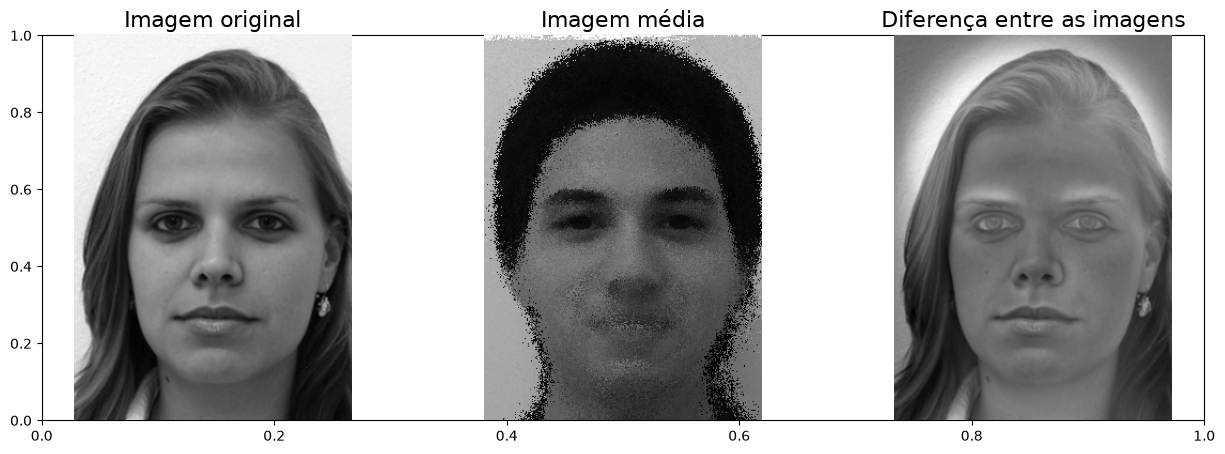

In [97]:
# Apresentando o resultado da diferença das imagens

# Configurando o tamanho da área de visualização
plt.subplots(figsize=(15, 5))

# Configurando a visualização da imagem original
plt.subplot(1,3,1)
plt.imshow(dataset[0,:,:], cmap='gray')
plt.title('Imagem original', fontsize=16)
plt.axis('off')

# Configurando a visualização da imagem média
plt.subplot(1,3,2)
plt.imshow(mode_file, cmap='gray')
plt.title('Imagem média', fontsize=16)
plt.axis('off')

# Configurando a visualização da diferença
plt.subplot(1,3,3)
plt.imshow(diferenca, cmap='gray')
plt.title('Diferença entre as imagens', fontsize=16)
plt.axis('off')

# Apresentando o resultado
plt.show()

# Comparação de todos os padrões